# Figure S28: Rare eQTL expression-reduction thresholds

Rare eQTL variant counts across expression-reduction thresholds at disease genes.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_INPUT_ROOT` to the
source result tables and `QTL_SUSIE_ROOT` to the separate fine-mapping tables.
Set `QTL_PAPER_ROOT` to the local reference directory and `QTL_SOURCE_ROOT`
to the figure checkout. Set these variables in R before running the cells.
Paths can contain spaces.

Run the cells from top to bottom. The cells show input reads, filters, joins,
counts, models, and plot construction. Intermediate objects stay in this R
session. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Source scripts

The processing steps below follow these preparation scripts. The source data are not included in Git.

- [fig5-s28](../../preparation/Fig5/prepare_s28.R): Rebuild the historical rare high-PIP ClinGen eQTL set and expression-reduction thresholds.

The notebook runs the processing in its own cells. The preparation guide lists the original input requirements and missing inputs.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
input_root <- Sys.getenv("QTL_INPUT_ROOT", source_root)
susie_root <- Sys.getenv("QTL_SUSIE_ROOT", input_root)
repo_root <- getwd()
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  if (grepl("[.]rds([.]gz)?$", relative, ignore.case = TRUE)) {
    stop("Saved RDS inputs are not used by these notebooks: ", relative, call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || dir.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  key <- paste(variable, relative, sep = ":")
  hash <- unname(tools::md5sum(path))
  previous <- input_records[[key]]
  if (!is.null(previous) && !identical(previous$md5, hash)) {
    stop("Input changed during notebook execution: ", relative, call. = FALSE)
  }
  if (is.null(previous)) input_records[[key]] <- list(root = variable, path = relative, md5 = hash)
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
input_file <- function(relative) checked_input(input_root, relative, "QTL_INPUT_ROOT")
susie_file <- function(relative) checked_input(susie_root, relative, "QTL_SUSIE_ROOT")
repo_file <- function(relative) checked_input(repo_root, relative, "QTL_REPO_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")
# Local source-result inputs and memory-only intermediate objects.
prep_root <- function(name) {
  value <- switch(name, paper = paper_root, source = source_root,
                  input = input_root, susie = susie_root,
                  stop("Unknown source root: ", name, call. = FALSE))
  if (!nzchar(value)) stop("Set the local ", name, " root before running the notebook.", call. = FALSE)
  value
}
.prep_root <- prep_root
prep_input <- function(root_name, relative) {
  variable <- c(paper = "QTL_PAPER_ROOT", source = "QTL_SOURCE_ROOT",
                input = "QTL_INPUT_ROOT", susie = "QTL_SUSIE_ROOT")[[root_name]]
  checked_input(prep_root(root_name), relative, variable)
}
prep_input_any <- function(root_name, candidates) {
  for (relative in candidates) {
    if (file.exists(file.path(prep_root(root_name), relative))) return(prep_input(root_name, relative))
  }
  stop("Missing source input under ", root_name, ": ", paste(candidates, collapse = ", "), call. = FALSE)
}
prep_input_file <- function(variable, fallback_root = "input", relative) {
  path <- Sys.getenv(variable)
  if (!nzchar(path)) return(prep_input_any(fallback_root, relative))
  checked_input(dirname(path), basename(path), paste0("env:", variable))
}
# Resolve recorded paths for the input-unchanged check. Records contain no
# machine-specific directory names; explicit file overrides retain their key.
recorded_input_path <- function(record) {
  if (startsWith(record$root, "env:")) return(Sys.getenv(sub("^env:", "", record$root)))
  root <- switch(record$root, QTL_PAPER_ROOT = paper_root,
                 QTL_SOURCE_ROOT = source_root, QTL_INPUT_ROOT = input_root,
                 QTL_SUSIE_ROOT = susie_root, QTL_REPO_ROOT = repo_root,
                 stop("Unknown recorded input root: ", record$root, call. = FALSE))
  file.path(root, record$path)
}

# These functions read the tracked result-table manifest. Each notebook starts
# with an empty memory store. An existing file cannot skip a calculation.
prep_result_runtime <- function(figure, envir = parent.frame()) {
  manifest <- readr::read_tsv(repo_file(file.path(figure, "inputs.tsv")),
    col_types = cols(.default = col_character()), na = c("", "-"), show_col_types = FALSE)
  computed <- new.env(parent = emptyenv())
  input_files <- function(key) {
    rows <- manifest[manifest$key == key, , drop = FALSE]
    if (!nrow(rows)) stop("Unknown result-table key: ", key, call. = FALSE)
    rows$path <- map_chr(rows$local_subpath, function(relative) {
      if (key == "clingen") {
        files <- list.files(file.path(prep_root("input"), relative), pattern = "[.]parquet$", full.names = FALSE)
        if (!length(files)) stop("No ClinGen parquet input under ", relative, call. = FALSE)
        return(prep_input("input", file.path(relative, sort(files)[1])))
      }
      candidates <- unique(c(relative, sub("splicing_SusieMerged[.]annotated", "splicing_SusieMerged..annotated", relative)))
      prep_input_any("input", candidates)
    })
    rows
  }
  input_path <- function(key) {
    rows <- input_files(key)
    if (nrow(rows) != 1L) stop("Expected one input for ", key, call. = FALSE)
    rows$path
  }
  load_input <- function(key, reader = data.table::fread, ..., attach_meta = TRUE) {
    rows <- input_files(key)
    metadata <- setdiff(names(rows), c("key", "local_subpath", "gs_uri", "source_repo", "source_workflow", "path"))
    map_dfr(seq_len(nrow(rows)), function(i) {
      data <- as_tibble(reader(rows$path[i], ...))
      if (attach_meta) for (column in metadata) if (!is.na(rows[[column]][i])) data[[column]] <- rows[[column]][i]
      data
    })
  }
  build_or_cache <- function(name, expr, refresh = FALSE) {
    if (!refresh && exists(name, envir = computed, inherits = FALSE)) return(computed[[name]])
    message("Calculate ", figure, "/", name, " from source result tables")
    value <- force(expr)
    computed[[name]] <- value
    value
  }
  for (name in c("input_files", "input_path", "load_input", "build_or_cache")) assign(name, get(name), envir = envir)
  invisible(computed)
}


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Source selection and threshold functions


In [2]:
# Pure transformations from the accepted Figure 5 preparation scripts.
# See provenance.json for the original scripts and their checksums.
fig5_populations <- c("afr", "amr", "eas", "eur", "mid", "sas")
fig5_af_columns <- paste0("gvs_", fig5_populations, "_af")

fig5_reference <- function(reference) {
  reference %>%
    filter(confidence %in% c("Strong", "Definitive")) %>%
    select(targetId, targetFromSourceId, allelicRequirements) %>%
    unnest(allelicRequirements) %>% distinct()
}

fig5_clinvar_class <- function(classification) {
  classification <- replace_na(str_to_lower(str_trim(classification)), "")
  case_when(classification == "" ~ "Unannotated",
    str_detect(classification, "pathogenic") ~ "P/LP",
    str_detect(classification, "uncertain") ~ "VUS",
    str_detect(classification, "benign") ~ "B/LB", TRUE ~ "Other")
}

fig5_select_pairs <- function(raw, reference) {
  raw %>%
    mutate(gene = str_extract(molecular_trait_id, "ENSG[0-9]+"),
      clinvar_classification = replace_na(clinvar_classification, "")) %>%
    filter(gvs_max_af < 0.01, gene %in% reference$targetId) %>% distinct()
}

fig5_assign_populations <- function(frequencies) {
  frequencies <- frequencies %>% select(variant, all_of(fig5_af_columns)) %>% distinct()
  stopifnot(!anyDuplicated(frequencies$variant),
    all(complete.cases(frequencies)),
    all(as.matrix(frequencies[fig5_af_columns]) >= 0),
    all(as.matrix(frequencies[fig5_af_columns]) <= 1))
  result <- frequencies %>%
    pivot_longer(all_of(fig5_af_columns), names_to = "population", values_to = "af") %>%
    mutate(population = str_remove_all(population, "gvs_|_af"),
      population = factor(population, levels = fig5_populations)) %>%
    arrange(variant, population) %>% group_by(variant) %>%
    summarise(max_six_af = max(af), eur_af = af[population == "eur"],
      population_A = as.character(population[which.max(af)]),
      tied_max = sum(af == max(af)),
      tied_populations = paste(as.character(population[af == max(af)]), collapse = ";"),
      .groups = "drop") %>%
    mutate(eur_comparable = eur_af >= 0.75 * max_six_af,
      population_B = if_else(eur_comparable, "eur", population_A),
      reassigned_in_B = population_B != population_A)
  stopifnot(all(result$max_six_af > 0))
  result
}

fig5_variant_assignments <- function(pairs, frequencies, reference = NULL) {
  if (!is.null(reference)) {
    pairs <- pairs %>% inner_join(reference %>%
      filter(allelicRequirements %in% c("AD", "AR")) %>%
      distinct(targetId, allelicRequirements),
      by = c("gene" = "targetId"), relationship = "many-to-many")
  } else if (!"allelicRequirements" %in% names(pairs)) {
    stop("Supply the ClinGen reference when pairs have no inheritance mode.")
  }
  selected <- pairs %>% filter(allelicRequirements %in% c("AD", "AR")) %>%
    group_by(allelicRequirements, variant) %>%
    summarise(InClinvar = any(!is.na(clinvar_classification) &
      str_trim(clinvar_classification) != ""),
      assays = paste(sort(unique(assay)), collapse = ";"),
      genes = paste(sort(unique(gene)), collapse = ";"),
      original_max_af = max(gvs_max_af), .groups = "drop")
  assignments <- selected %>% left_join(
    fig5_assign_populations(frequencies %>% filter(variant %in% selected$variant)),
    by = "variant", relationship = "many-to-one")
  stopifnot(!anyDuplicated(assignments[c("allelicRequirements", "variant")]),
    !anyNA(assignments$population_A), !anyNA(assignments$population_B))
  assignments
}

fig5_counts_and_classes <- function(assignments, pairs) {
  counts <- assignments %>% count(allelicRequirements, population = population_A,
    name = "total") %>% mutate(population = factor(population, levels = fig5_populations)) %>%
    complete(allelicRequirements, population, fill = list(total = 0)) %>%
    arrange(allelicRequirements, population)
  coverage <- assignments %>% group_by(allelicRequirements, population = population_B) %>%
    summarise(in_clinvar = sum(InClinvar), total = n(), .groups = "drop") %>%
    mutate(percent = 100 * in_clinvar / total,
      population = factor(population, levels = fig5_populations),
      emphasis = if_else(population == "eur", "EUR", "Other groups"),
      label = sprintf("%.1f", percent)) %>% arrange(allelicRequirements, population)
  classes <- pairs %>% semi_join(assignments %>% distinct(variant), by = "variant") %>%
    group_by(variant) %>%
    summarise(annotation_strings = n_distinct(na_if(str_trim(clinvar_classification), ""),
      na.rm = TRUE), classification = paste(sort(unique(na.omit(
        na_if(str_to_lower(str_trim(clinvar_classification)), "")
      ))), collapse = ";"), .groups = "drop") %>%
    mutate(clinvar_class = fig5_clinvar_class(classification))
  stopifnot(all(classes$annotation_strings <= 1), !any(classes$clinvar_class == "Other"))
  selected_classes <- assignments %>% select(allelicRequirements, variant, InClinvar) %>%
    left_join(classes, by = "variant", relationship = "many-to-one")
  stopifnot(!anyNA(selected_classes$clinvar_class),
    all(selected_classes$InClinvar == (selected_classes$clinvar_class != "Unannotated")))
  proportions <- selected_classes %>% count(allelicRequirements, clinvar_class, name = "n") %>%
    mutate(clinvar_class = factor(clinvar_class,
      levels = c("P/LP", "VUS", "B/LB", "Unannotated"))) %>%
    arrange(allelicRequirements, clinvar_class) %>% group_by(allelicRequirements) %>%
    mutate(total = sum(n), proportion = n / total, xmax = cumsum(proportion),
      xmin = xmax - proportion, label = scales::percent(proportion, accuracy = 0.1)) %>%
    ungroup()
  list(counts = counts, coverage = coverage, classes = selected_classes,
    proportions = proportions)
}

fig5_funnel <- function(raw, reference) {
  symbols <- reference %>% distinct(gene = targetId, symbol = targetFromSourceId)
  stopifnot(!anyDuplicated(symbols$gene))
  ar_genes <- reference %>% filter(allelicRequirements == "AR") %>% pull(targetId)
  baseline <- raw %>% select(variant, molecular_trait_id, gvs_max_af, pip,
    posterior_mean, clinvar_classification, assay) %>%
    mutate(gene = str_extract(molecular_trait_id, "ENSG[0-9]+"),
      clinvar_classification = replace_na(str_to_lower(clinvar_classification), ""),
      is_pathogenic = str_detect(clinvar_classification, "pathogenic")) %>%
    filter(gvs_max_af < 0.01, gene %in% ar_genes,
      clinvar_classification == "" |
        str_detect(clinvar_classification, "uncertain|pathogenic")) %>% distinct()
  sets <- list(rare_all = baseline, pip09 = baseline %>% filter(pip > 0.9),
    posterior_lt_neg03 = baseline %>% filter(pip > 0.9,
      is.finite(posterior_mean), posterior_mean < -0.3))
  counts <- imap_dfr(sets, function(data, stage) {
    data %>% summarise(variants = n_distinct(variant), genes = n_distinct(gene),
      pathogenic_variants = n_distinct(variant[is_pathogenic])) %>%
      mutate(stage = stage, .before = 1)
  }) %>% mutate(pathogenic_pct = 100 * pathogenic_variants / variants,
    enrichment = pathogenic_pct / first(pathogenic_pct))
  final_pairs <- sets$pip09 %>%
    semi_join(sets$posterior_lt_neg03 %>% distinct(gene), by = "gene") %>%
    mutate(is_unclassified = str_trim(replace_na(clinvar_classification, "")) == "",
      is_vus = !is_pathogenic & str_detect(clinvar_classification, "uncertain"),
      is_candidate = is_unclassified | is_vus,
      passes_previous_effect_filter = is.finite(posterior_mean) & posterior_mean < -0.3,
      positive_effect = is.finite(posterior_mean) & posterior_mean > 0)
  annotations <- final_pairs %>% distinct(variant, is_pathogenic, is_unclassified,
    is_vus, is_candidate)
  stopifnot(!anyDuplicated(annotations$variant),
    !any(final_pairs$is_pathogenic & final_pairs$is_candidate))
  audit <- final_pairs %>% group_by(gene) %>%
    summarise(variants = n_distinct(variant),
      pathogenic_variants = n_distinct(variant[is_pathogenic]),
      unclassified_variants = n_distinct(variant[is_unclassified]),
      vus_variants = n_distinct(variant[is_vus]),
      candidate_variants = n_distinct(variant[is_candidate]),
      previous_stage_variants = n_distinct(variant[passes_previous_effect_filter]),
      negative_pathogenic_variants = n_distinct(variant[is_pathogenic & passes_previous_effect_filter]),
      negative_candidate_variants = n_distinct(variant[is_candidate & passes_previous_effect_filter]),
      positive_candidate_variants = n_distinct(variant[is_candidate & positive_effect]),
      pathogenic_assays = paste(sort(unique(assay[is_pathogenic])), collapse = ";"),
      candidate_assays = paste(sort(unique(assay[is_candidate])), collapse = ";"),
      .groups = "drop") %>%
    mutate(retained = pathogenic_variants > 0 & candidate_variants > 0,
      retained_under_previous_rule = negative_pathogenic_variants > 0 &
        negative_candidate_variants > 0) %>%
    left_join(symbols, by = "gene") %>% relocate(symbol, .after = gene) %>%
    arrange(symbol, gene)
  selected <- final_pairs %>% semi_join(audit %>% filter(retained), by = "gene") %>%
    left_join(symbols, by = "gene") %>% relocate(symbol, .after = gene) %>%
    arrange(symbol, variant, assay, molecular_trait_id)
  stages <- bind_rows(counts, selected %>% summarise(
    stage = "pathogenic_and_unclassified_or_vus_high_pip_same_gene",
    variants = n_distinct(variant), genes = n_distinct(gene),
    pathogenic_variants = n_distinct(variant[is_pathogenic]),
    pathogenic_pct = NA_real_, enrichment = NA_real_))
  list(stages = stages, sets = sets, audit = audit, selected_pairs = selected,
    shared_genes = audit %>% filter(retained))
}

fig5_subset_test <- function(universe_pairs, selected_pairs, selected_stage,
    universe_stage, comparison) {
  universe <- universe_pairs %>% distinct(variant, is_pathogenic)
  selected <- selected_pairs %>% distinct(variant)
  stopifnot(!anyDuplicated(universe$variant), !anyNA(universe$is_pathogenic),
    all(selected$variant %in% universe$variant))
  classified <- universe %>% mutate(retained = variant %in% selected$variant)
  a <- sum(classified$retained & classified$is_pathogenic)
  b <- sum(classified$retained & !classified$is_pathogenic)
  c <- sum(!classified$retained & classified$is_pathogenic)
  d <- sum(!classified$retained & !classified$is_pathogenic)
  table <- matrix(c(a, b, c, d), nrow = 2, byrow = TRUE)
  fit <- fisher.test(table, alternative = "two.sided", conf.level = 0.95)
  one_sided <- fisher.test(table, alternative = "greater", conf.int = FALSE)
  tibble(comparison, selected_stage, universe_stage,
    retained_pathogenic = a, retained_other = b,
    not_retained_pathogenic = c, not_retained_other = d,
    universe_variants = nrow(universe), universe_pathogenic = a + c,
    retained_variants = a + b, retained_pathogenic_percent = 100 * a / (a + b),
    universe_pathogenic_percent = 100 * (a + c) / nrow(universe),
    enrichment_vs_universe = (a / (a + b)) / ((a + c) / nrow(universe)),
    odds_ratio_vs_not_retained = unname(fit$estimate), OR_lower_95 = fit$conf.int[[1]],
    OR_upper_95 = fit$conf.int[[2]], p_value_two_sided = fit$p.value,
    p_value_one_sided_greater = one_sided$p.value, correction = "none",
    test = "Fisher exact; retained versus disjoint complement")
}

fig5_coverage_test <- function(mode, comparison, annotated, total, eur_annotated, eur_total) {
  fit <- fisher.test(matrix(c(annotated, total - annotated, eur_annotated,
    eur_total - eur_annotated), nrow = 2, byrow = TRUE), alternative = "two.sided")
  tibble(allelicRequirements = mode, comparison,
    annotated_comparison = annotated, unannotated_comparison = total - annotated,
    total_comparison = total, percent_comparison = 100 * annotated / total,
    annotated_eur = eur_annotated, unannotated_eur = eur_total - eur_annotated,
    total_eur = eur_total, percent_eur = 100 * eur_annotated / eur_total,
    odds_ratio = unname(fit$estimate), ci_95_lower = fit$conf.int[[1]],
    ci_95_upper = fit$conf.int[[2]], p_two_sided = fit$p.value)
}

fig5_coverage_tests <- function(coverage, assignments) {
  pooled <- coverage %>% mutate(group = if_else(population == "eur", "EUR", "non_EUR")) %>%
    group_by(allelicRequirements, group) %>%
    summarise(annotated = sum(in_clinvar), total = sum(total), .groups = "drop")
  pooled_tests <- map_dfr(c("AD", "AR"), function(mode) {
    non_eur <- pooled %>% filter(allelicRequirements == mode, group == "non_EUR")
    eur <- pooled %>% filter(allelicRequirements == mode, group == "EUR")
    fig5_coverage_test(mode, "Pooled non-EUR", non_eur$annotated, non_eur$total,
      eur$annotated, eur$total)
  }) %>% mutate(p_holm_two_pooled_tests = p.adjust(p_two_sided, "holm"))
  group_tests <- coverage %>% filter(population != "eur") %>%
    pmap_dfr(function(allelicRequirements, population, in_clinvar, total, ...) {
      eur <- coverage %>% filter(.data$allelicRequirements == .env$allelicRequirements,
        .data$population == "eur")
      fig5_coverage_test(allelicRequirements, str_to_upper(population), in_clinvar,
        total, eur$in_clinvar, eur$total)
    }) %>% mutate(p_holm_ten_group_tests = p.adjust(p_two_sided, "holm"),
      significant_holm_0_05 = p_holm_ten_group_tests < 0.05)
  union <- assignments %>% distinct(variant, population_B, InClinvar)
  stopifnot(!anyDuplicated(union$variant))
  totals <- union %>% mutate(group = if_else(population_B == "eur", "EUR", "non_EUR")) %>%
    group_by(group) %>% summarise(annotated = sum(InClinvar), total = n(), .groups = "drop")
  non_eur <- totals %>% filter(group == "non_EUR")
  eur <- totals %>% filter(group == "EUR")
  overall <- fig5_coverage_test("AD/AR union", "Pooled non-EUR",
    non_eur$annotated, non_eur$total, eur$annotated, eur$total)
  all_tests <- bind_rows(pooled_tests %>% mutate(test_family = "Two pooled comparisons"),
    group_tests %>% mutate(test_family = "Ten individual group comparisons"),
    overall %>% mutate(test_family = "Supplemental unique-variant union")) %>%
    mutate(p_holm_all_13 = p.adjust(p_two_sided, "holm"))
  list(pooled = pooled_tests, groups = group_tests, overall = overall, all = all_tests)
}

fig5_threshold_tables <- function(selected, thresholds) {
  variants <- selected %>% group_by(variant) %>%
    summarise(target_genes = paste(sort(unique(gene)), collapse = ";"),
      n_target_genes = n_distinct(gene), min_log2_aFC = min(log2_aFC),
      max_log2_aFC = max(log2_aFC), .groups = "drop") %>%
    mutate(max_reduction_pct = 100 * (1 - 2^min_log2_aFC))
  denominator <- nrow(variants)
  counts <- tibble(reduction_threshold_pct = thresholds) %>%
    mutate(afc_ratio_cutoff = 1 - reduction_threshold_pct / 100,
      log2_afc_cutoff = log2(afc_ratio_cutoff),
      variants = map_int(log2_afc_cutoff, ~ sum(variants$min_log2_aFC < .x)),
      total_assessed = denominator, percent_of_all_variants = 100 * variants / total_assessed)
  list(variants = variants, counts = counts)
}

fig5_effect_panels <- function(raw, funnel, reference) {
  symbols <- reference %>% distinct(gene = targetId, symbol = targetFromSourceId)
  annotated <- raw %>% mutate(gene = str_extract(molecular_trait_id, "ENSG[0-9]+")) %>%
    left_join(symbols, by = "gene", relationship = "many-to-one")
  d_order <- c("HEXA", "PMM2", "GALM")
  d_benign_audit <- annotated %>% filter(symbol %in% d_order, pip > 0.9,
    str_detect(replace_na(clinvar_classification, ""), "benign"),
    !str_detect(replace_na(clinvar_classification, ""), "uncertain|pathogenic")) %>%
    select(variant, molecular_trait_id, pip, posterior_mean, gvs_max_af,
      gvs_max_subpop, clinvar_classification, consequence, gene, assay, symbol) %>% distinct()
  benign <- d_benign_audit %>% filter(!str_detect(replace_na(consequence, ""), "missense")) %>%
    mutate(assay_priority = match(assay, c("pQTL", "eQTL", "sQTL"))) %>%
    arrange(symbol, variant, assay_priority, desc(pip), molecular_trait_id) %>%
    distinct(symbol, variant, .keep_all = TRUE) %>%
    mutate(is_pathogenic = FALSE, is_vus = FALSE, is_unclassified = FALSE, is_benign = TRUE)
  targets <- bind_rows(funnel$selected_pairs %>% filter(symbol %in% d_order) %>%
    mutate(is_benign = FALSE), benign) %>% select(-any_of(c("gvs_max_subpop", "consequence")))
  annotations <- annotated %>% select(variant, molecular_trait_id, assay,
    gvs_max_subpop, consequence, source_pip = pip, source_effect = posterior_mean) %>%
    semi_join(targets, by = c("variant", "molecular_trait_id", "assay")) %>% distinct()
  d <- targets %>% left_join(annotations, by = c("variant", "molecular_trait_id", "assay"),
    relationship = "one-to-one") %>%
    mutate(symbol = factor(symbol, d_order),
      clinvar = case_when(is_pathogenic ~ "P/LP", is_vus ~ "VUS",
        is_unclassified ~ "Unclassified", is_benign ~ "B/LB"),
      ancestry = recode(str_to_upper(gvs_max_subpop), OTH = "REM"),
      ancestry = if_else(symbol == "HEXA" & variant == "chr15_72346579_G_GGATA" &
        is_pathogenic, "ASJ\n[REM]", ancestry), effect = posterior_mean,
      clinvar_classification = na_if(clinvar_classification, "")) %>%
    arrange(symbol, desc(effect), variant) %>%
    mutate(x = row_number() + (as.integer(symbol) - 1) * 1.4,
      label_y = effect + if_else(effect > 0, 0.15, -0.14))
  stopifnot(all(abs(d$effect - d$source_effect) < 1e-10),
    all(abs(d$pip - d$source_pip) < 1e-10))
  d <- d %>% select(symbol, gene, variant, assay, molecular_trait_id, clinvar,
    clinvar_classification, pip, effect, ancestry, gvs_max_af, consequence, x, label_y)

  negative <- funnel$sets$posterior_lt_neg03
  comparisons <- negative %>% filter(!is_pathogenic) %>%
    inner_join(negative %>% filter(is_pathogenic) %>%
      select(gene, assay, molecular_trait_id, reference_variant = variant,
        reference_effect = posterior_mean),
      by = c("gene", "assay", "molecular_trait_id"), relationship = "many-to-many") %>%
    filter(variant != reference_variant) %>%
    mutate(effect_ratio = abs(posterior_mean) / abs(reference_effect)) %>%
    left_join(symbols, by = "gene")
  selected_comparisons <- comparisons %>% filter(effect_ratio >= 0.9)
  e_targets <- bind_rows(selected_comparisons %>%
    transmute(symbol, assay, variant, role = "candidate"),
    selected_comparisons %>% transmute(symbol, assay,
      variant = reference_variant, role = "reference")) %>% distinct()
  e_rare <- annotated %>% inner_join(e_targets, by = c("symbol", "assay", "variant")) %>%
    distinct(symbol, assay, variant, .keep_all = TRUE) %>%
    mutate(clinvar = fig5_clinvar_class(clinvar_classification),
      clinvar = recode(clinvar, Unannotated = "Unclassified"),
      consequence = NA_character_)
  # These benign comparators were selected explicitly in slide_with_benign.R.
  benign_targets <- tribble(~symbol, ~assay, ~variant,
    "GAA", "eQTL", "chr17_80101663_G_C", "SMPD1", "pQTL", "chr11_6394233_G_A",
    "CTH", "pQTL", "chr1_70439117_G_T", "PLG", "pQTL", "chr6_160716734_G_A",
    "PLG", "pQTL", "chr6_160731873_C_T", "CC2D1A", "pQTL", "chr19_13913456_C_T",
    "CC2D1A", "pQTL", "chr19_13920915_T_C")
  e_benign <- annotated %>% inner_join(benign_targets,
    by = c("symbol", "assay", "variant")) %>% filter(pip > 0.9) %>%
    distinct(symbol, assay, variant, .keep_all = TRUE) %>%
    filter(!str_detect(replace_na(consequence, ""), "missense")) %>%
    filter(!(symbol == "PLG" & variant == "chr6_160716734_G_A"),
      !(symbol == "SMPD1" & variant == "chr11_6394233_G_A")) %>%
    mutate(clinvar = "B/LB", role = "benign comparator")
  acy <- annotated %>% semi_join(funnel$selected_pairs %>% filter(symbol == "ACY1"),
    by = c("symbol", "assay", "variant", "molecular_trait_id")) %>%
    mutate(clinvar = fig5_clinvar_class(clinvar_classification),
      clinvar = recode(clinvar, Unannotated = "Unclassified"),
      role = if_else(clinvar == "P/LP", "reference", "candidate"), consequence = NA_character_)
  e <- bind_rows(e_rare, e_benign, acy) %>%
    mutate(symbol = factor(symbol, c("GAA", "SMPD1", "CTH", "PLG", "CC2D1A", "ACY1")),
      effect = posterior_mean, ancestry = recode(str_to_upper(gvs_max_subpop), OTH = "REM")) %>%
    arrange(symbol, desc(effect)) %>%
    mutate(x = row_number() + (as.integer(symbol) - 1) * 1.3,
      label_y = effect + if_else(effect > 0, 0.15, -0.14),
      label_y = if_else(symbol == "CC2D1A" & ancestry == "REM", effect - 0.31, label_y)) %>%
    select(symbol, assay, variant, role, effect, pip, clinvar, clinvar_classification,
      ancestry, gvs_max_af, consequence, x, label_y)
  list(D = d, E = e, benign_audit = d_benign_audit, comparisons = comparisons)
}

# The accepted S31 locus object supplies layout, cCRE, and gene-track rendering.
# Replace every QTL plotting frame with source-derived values. Fail if the
# accepted renderer no longer covers the source variants or their coordinates.
fig5_refresh_locus_template <- function(template, qtl) {
  prepared <- qtl %>% filter(!is.na(position), !is.na(pip)) %>%
    mutate(rare = gvs_max_af < 0.01, causal = pip >= 0.9,
      type = "Expression", in_zoom = abs(position - 51912316) <= 500)
  stopifnot(!anyDuplicated(prepared$variant))
  seen <- character()
  replace_frame <- function(data) {
    if (!is.data.frame(data) || !all(c("variant", "position", "pip") %in% names(data))) {
      return(data)
    }
    matched <- match(data$variant, prepared$variant)
    if (anyNA(matched)) stop("The S31 locus renderer has a variant absent from the source.")
    source <- prepared[matched, , drop = FALSE]
    columns <- intersect(c("position", "pip", "cs_id", "gvs_max_af", "rare", "causal",
      "type", "in_zoom"), names(data))
    canonical <- function(frame) as_tibble(frame) %>% select(all_of(columns)) %>%
      mutate(across(where(is.factor), as.character))
    if (!isTRUE(all.equal(canonical(data), canonical(source),
        check.attributes = FALSE, tolerance = 1e-10))) {
      stop("Source QTL values differ from the accepted S31 locus renderer.")
    }
    result <- as_tibble(data)
    for (column in columns) {
      value <- source[[column]]
      if (is.factor(data[[column]])) value <- factor(value, levels = levels(data[[column]]))
      result[[column]] <- value
    }
    seen <<- union(seen, source$variant)
    result
  }
  update <- function(plot) {
    plot$data <- replace_frame(plot$data)
    plot$layers <- lapply(plot$layers, function(layer) {
      copy <- ggplot2::ggproto(NULL, layer)
      copy$data <- replace_frame(layer$data)
      copy
    })
    if (inherits(plot, "patchwork")) {
      plot$patches$plots <- lapply(plot$patches$plots, update)
    }
    plot
  }
  result <- update(template)
  if (!setequal(seen, prepared$variant)) {
    stop("The accepted S31 locus renderer does not cover every prepared variant.")
  }
  result
}


## Select rare eQTL variants and calculate expression-reduction thresholds

Keep PIP >0.9, maximum AF <1%, ClinGen targets, and uncertain or empty ClinVar records. Deduplicate variants after choosing the strongest decreasing effect.


In [3]:
message("Read the original S28 expression and ClinGen inputs.")
raw <- as_tibble(data.table::fread(prep_input("input",
  "COMB.expression_SusieMerged.annotated.ancestry_skew.tsv.gz"),
  select = c("variant", "molecular_trait_id", "gvs_max_af", "pip",
    "clinvar_classification", "log2_aFC"), na.strings = "NA"))
reference <- arrow::read_parquet(prep_input("input",
  "part-00000-006c7897-e219-4036-abbf-af4482a5177e-c000.snappy.parquet")) %>%
  as_tibble() %>% fig5_reference()
selected <- raw %>%
  mutate(clinvar_classification = replace_na(clinvar_classification, ""),
    gene = str_extract(molecular_trait_id, "ENSG[0-9]+")) %>%
  filter(gvs_max_af < 0.01, pip > 0.9,
    str_detect(clinvar_classification, "uncertain") | clinvar_classification == "",
    gene %in% reference$targetId) %>%
  select(variant, gene, log2_aFC, clinvar_classification, pip, gvs_max_af)
stopifnot(nrow(selected) == 576L, n_distinct(selected$variant) == 574L,
  n_distinct(selected$gene) == 453L, all(is.finite(selected$log2_aFC)))
curve_result <- fig5_threshold_tables(selected, seq(0, 100, by = 1))
landmark_result <- fig5_threshold_tables(selected,
  sort(unique(c(seq(0, 100, by = 5), 100 * (1 - 2^-0.5), 99))))
curve <- curve_result$counts
landmarks <- landmark_result$counts
dots <- landmarks %>% filter(reduction_threshold_pct %in% c(0, 10, 20, 25, 40, 50, 60, 70, 75, 80, 90, 95, 100) |
                              abs(log2_afc_cutoff + 0.5) < 1e-10)
half <- landmarks %>% filter(reduction_threshold_pct == 50)
legacy <- landmarks %>% filter(abs(log2_afc_cutoff + 0.5) < 1e-10)
stopifnot(all(curve$total_assessed == 574L), all(diff(curve$variants) <= 0),
          half$variants == 45L, legacy$variants == 105L)


Read the original S28 expression and ClinGen inputs.


## Draw the calculated thresholds

Expression reduction is 100 × (1 − 2^log2_aFC). A variant passes a threshold when at least one qualifying target has a strictly greater reduction. Straight lines join selected threshold points as in the current source figure; they do not estimate the intervening empirical counts.


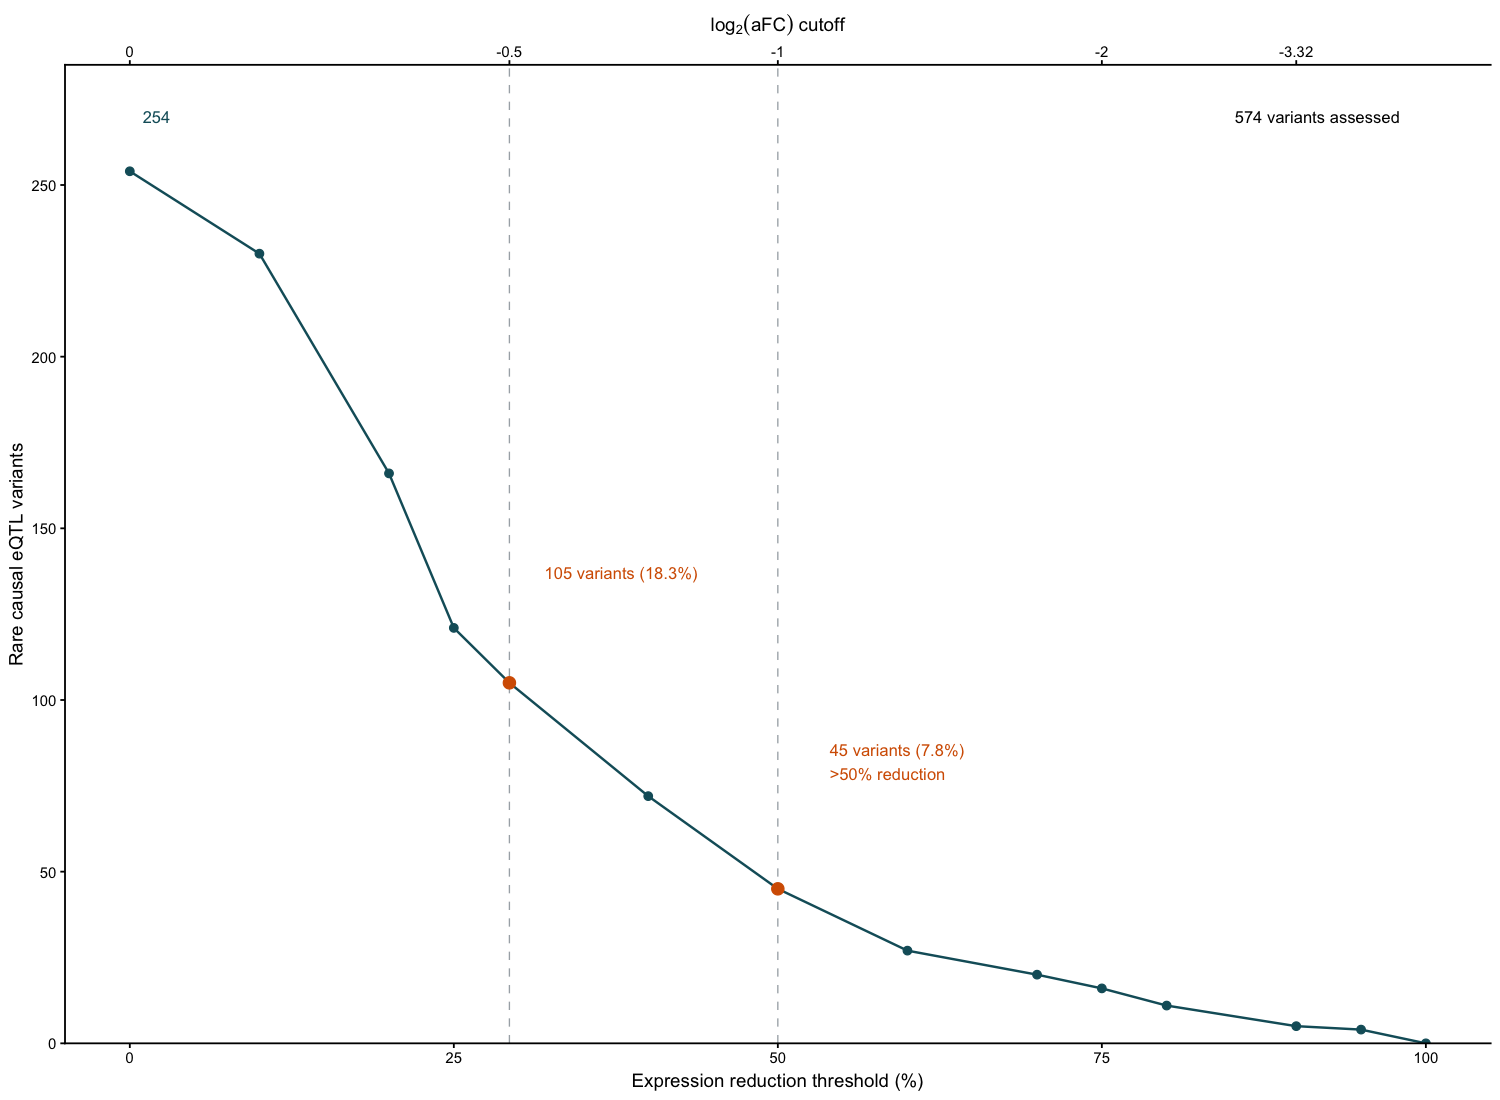

In [4]:
top_breaks <- 100 * (1 - 2^c(0, -0.5, -1, -2, -log2(10)))
figure <- ggplot(dots, aes(reduction_threshold_pct, variants)) +
  geom_vline(xintercept = c(legacy$reduction_threshold_pct, 50), colour = "#A8AFB4", linewidth = 0.3, linetype = "dashed") +
  geom_line(linewidth = 0.55, colour = "#145D69") +
  geom_point(size = 1.65, colour = "#145D69") +
  geom_point(data = bind_rows(legacy, half), size = 2.5, colour = "#D55E00") +
  annotate("text", x = 1, y = 270, label = "254", hjust = 0, size = 2.8, colour = "#145D69") +
  annotate("text", x = 98, y = 270, label = "574 variants assessed", hjust = 1, size = 2.8) +
  annotate("text", x = 32, y = 137, label = "105 variants (18.3%)", hjust = 0, size = 2.8, colour = "#D55E00") +
  annotate("text", x = 54, y = 82, label = "45 variants (7.8%)\n>50% reduction", hjust = 0, size = 2.8, colour = "#D55E00") +
  scale_x_continuous(limits = c(0, 100), breaks = seq(0, 100, 25),
                     sec.axis = dup_axis(breaks = top_breaks, labels = c("0", "-0.5", "-1", "-2", "-3.32"),
                                         name = expression(log[2](aFC)~cutoff))) +
  scale_y_continuous(limits = c(0, 285), breaks = seq(0, 250, 50), expand = expansion(mult = 0)) +
  labs(x = "Expression reduction threshold (%)", y = "Rare causal eQTL variants") + theme_classic(base_size = 9)
print(figure)


## Save aggregate outputs

Save the figure and threshold counts. There is no new significance test. The 105/574 value is at log2(aFC) < −0.5, or approximately 29.3% reduction. The >50% value is 45/574.


In [5]:
save_plot(figure, "supplements/S28", 130, 100)
readr::write_tsv(landmarks, output_file("supplements/S28_threshold_counts.tsv"))


Export aggregate plot: supplements/S28
